<h1> <center> Real Estate Housing Price Prediction </center> </h1>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv('data/raw.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 1. Exploratory Data Analysis

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [4]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [5]:
# List of colonnes

columns = df.columns
print(f"The list of columns is :\n {list(columns)}")

The list of columns is :
 ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


In [6]:
# List of null values
print(f"The list of null values : \n{df.isnull().sum()}")

The list of null values : 
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [9]:
# List of duplicates
print(f"The list of duplicates : {df.duplicated().sum()}")

The list of duplicates : 0


In [ ]:
# Types of data
df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

###  Dealing with null values for the column 'total_bedrooms'


In [36]:
df[df['total_bedrooms'].isna()]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
290,-122.16,37.77,47.0,1256.0,NaN,570.0,218.0,4.3750,161900.0,NEAR BAY
341,-122.17,37.75,38.0,992.0,NaN,732.0,259.0,1.6196,85100.0,NEAR BAY
538,-122.28,37.78,29.0,5154.0,NaN,3741.0,1273.0,2.5762,173400.0,NEAR BAY
563,-122.24,37.75,45.0,891.0,NaN,384.0,146.0,4.9489,247100.0,NEAR BAY
696,-122.10,37.69,41.0,746.0,NaN,387.0,161.0,3.9063,178400.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20267,-119.19,34.20,18.0,3620.0,NaN,3171.0,779.0,3.3409,220500.0,NEAR OCEAN
20268,-119.18,34.19,19.0,2393.0,NaN,1938.0,762.0,1.6953,167400.0,NEAR OCEAN
20372,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,410700.0,<1H OCEAN
20460,-118.75,34.29,17.0,5512.0,NaN,2734.0,814.0,6.6073,258100.0,<1H OCEAN


In [37]:
# Replace Nan with 0
df['total_bedrooms'].fillna(0, inplace= True)

df[df['total_bedrooms'].isna()]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity


In [39]:
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

#### Column 'Longitude'

In [54]:
df['longitude'].min(), df['longitude'].max()

(-124.35, -114.31)

#### Column 'Latitude'

In [56]:
df['latitude'].min(), df['latitude'].max()

(32.54, 41.95)

#### Column 'housing_median_age'

In [61]:
# housing_median_age    
df['housing_median_age'].min(), df['housing_median_age'].max()

(1.0, 52.0)

### Column 'total_rooms'

In [62]:
df['total_rooms'].min(), df['total_rooms'].max()

(2.0, 39320.0)

In [69]:
df[['total_rooms']].value_counts()

total_rooms
1527.0         18
1582.0         17
1613.0         17
2127.0         16
1722.0         15
               ..
4698.0          1
4690.0          1
4687.0          1
4685.0          1
39320.0         1
Name: count, Length: 5926, dtype: int64

There are some outliers in this column.

### Column 'total_bedrooms'

In [70]:
df['total_bedrooms'].min(), df['total_bedrooms'].max()

(0.0, 6445.0)

### Column 'population'

In [71]:
df['population'].min(), df['population'].max()

(3.0, 35682.0)

### Column 'households'

In [72]:
df['households'].min(), df['households'].max()

(1.0, 6082.0)

### Column 'median_income'      

In [73]:
df['median_income'].min(), df['median_income'].max()

(0.4999, 15.0001)

### Column 'median_house_value'

In [74]:
df['median_house_value'].min(), df['median_house_value'].max()

(14999.0, 500001.0)

### Column 'ocean_proximity'

In [75]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [91]:
labels = set(df['ocean_proximity'].values)

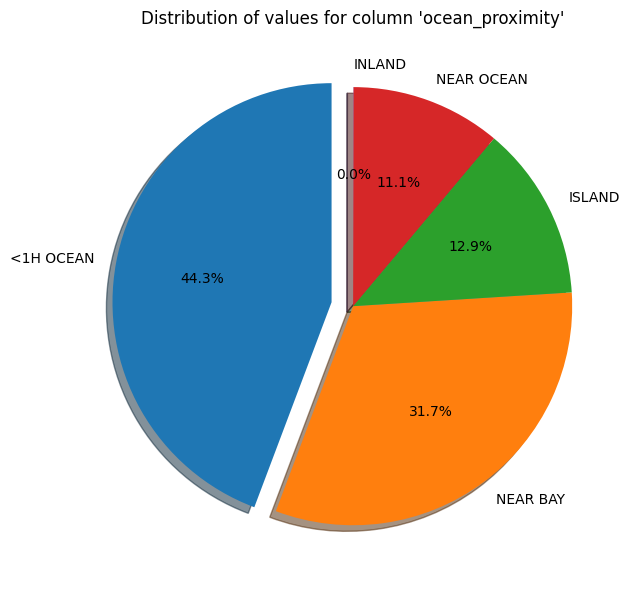

In [102]:
plt.figure(figsize=(12,6))
plt.pie(df[['ocean_proximity']].value_counts(),
        autopct= '%1.1f%%',
        startangle= 90,
        shadow= True,
        explode= [0.1, 0, 0, 0, 0],
        labels= labels)
plt.title("Distribution of values for column 'ocean_proximity'")
plt.grid(True)
plt.tight_layout()
plt.show()

{'<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'}